# AI Usage Data: Cleaning and Visualization

> **Synthetic data.** The dataset was generated for educational purposes by its author, with missing values, duplicates, inconsistent categories and mixed number formats added on purpose. Nothing here describes real students or professionals.

All numbers below come from running this notebook. Cleaning logic lives in `src/clean.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import clean as cl
from validate_raw import raw_report

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)

## 1. Raw data validation

In [2]:
raw = cl.load_raw()
print("shape:", raw.shape)
print("exact duplicate rows:", int(raw.duplicated().sum()))
print("duplicated User_ID:", int(raw["User_ID"].duplicated().sum()))
print("total missing cells:", int(raw.isna().sum().sum()), "| rows with any missing:", int(raw.isna().any(axis=1).sum()))
raw_report(raw)

shape: (300, 19)
exact duplicate rows: 12
duplicated User_ID: 12
total missing cells: 204 | rows with any missing: 151


,column,dtype,missing,missing_pct,unique,non_numeric_values,numeric_min,numeric_max
0,User_ID,str,0,0.0,288,300,NaN,NaN
1,Age,str,23,7.7,52,14,16.0,97.0
2,Gender,str,10,3.3,11,290,NaN,NaN
3,Country,str,10,3.3,20,290,NaN,NaN
4,User_Type,str,0,0.0,2,300,NaN,NaN
5,Education_Level,str,13,4.3,16,287,NaN,NaN
6,Profession,str,15,5.0,126,285,NaN,NaN
7,Monthly_Income,str,10,3.3,233,6,0.0,250000.0
8,AI_Tool,str,11,3.7,16,289,NaN,NaN
9,AI_Purpose,str,13,4.3,8,287,NaN,NaN


## 2. Cleaning
Steps: drop exact duplicates → strip units (`$`, `,`, `hrs`, `yrs`) and convert to numbers → map category spellings with explicit tables → flag (not remove) outliers. No imputation.

In [3]:
df, log_df, map_df = cl.clean(raw)
df.to_csv(cl.CLEAN_FILE, index=False)
log_df.to_csv(cl.LOG_FILE, index=False)
map_df.to_csv(cl.MAPPING_FILE, index=False)
log_df

,step,column,detail,count
0,load,*,raw rows,300
1,drop_exact_duplicates,*,exact duplicate rows removed,12
2,strip_units,Age,values with unit/symbol stripped,12
3,strip_units,Age,values that could not be converted,0
4,strip_units,Monthly_Income,values with unit/symbol stripped,6
5,strip_units,Monthly_Income,values that could not be converted,0
6,strip_units,AI_Usage_Hours_Per_Day,values with unit/symbol stripped,21
7,strip_units,AI_Usage_Hours_Per_Day,values that could not be converted,0
8,strip_units,Monthly_AI_Cost,values with unit/symbol stripped,15
9,strip_units,Monthly_AI_Cost,values that could not be converted,0


## 3. Cleaning verification

In [4]:
cl.before_after_summary(raw, df)

,column,dtype_before,dtype_after,unique_before,unique_after,missing_before,missing_after
0,User_ID,str,str,288,288,0,0
1,Age,str,float64,52,41,23,25
2,Gender,str,str,11,3,10,10
3,Country,str,str,20,12,10,10
4,User_Type,str,str,2,2,0,0
5,Education_Level,str,str,16,6,13,12
6,Profession,str,str,126,126,15,14
7,Monthly_Income,str,float64,233,230,10,11
8,AI_Tool,str,str,16,8,11,10
9,AI_Purpose,str,str,8,8,13,13


In [5]:
map_df[map_df['changed'] & (map_df['rows'] > 0)]

,column,raw_value,standard_value,rows,changed
1,Gender,male,Male,12,True
2,Gender,MALE,Male,6,True
3,Gender,M,Male,11,True
5,Gender,female,Female,3,True
6,Gender,FEMALE,Female,5,True
7,Gender,F,Female,10,True
9,Gender,other,Other,3,True
10,Gender,Non-binary,Other,1,True
12,AI_Tool,chatgpt,ChatGPT,4,True
13,AI_Tool,Chat GPT,ChatGPT,3,True


In [6]:
checks = cl.run_checks(raw, df)
assert checks["passed"].all(), checks[~checks["passed"]]
checks

,check,passed
0,no exact duplicate rows,True
1,User_ID unique,True
2,row count = raw - exact duplicates,True
3,numeric columns are numeric,True
4,NaN only from raw + nulled impossible values,True
5,no impossible values left,True
6,"Gender in {Male, Female, Other}",True
7,AI_Tool unique = 8,True
8,Education_Level unique = 6,True
9,Country unique = 12,True


In [7]:
flag_cols = [c for c in df.columns if c.startswith("flag_")]
show = ["User_ID", "Age", "User_Type", "Monthly_Income", "AI_Usage_Hours_Per_Day",
        "Time_Saved_Hours_Per_Week", "Work_or_Study_Hours_Per_Day"]
print(df[flag_cols].sum())
df[df[flag_cols].any(axis=1) & ~df["flag_usage_gt_work"]][show]

flag_age_over_80               2
flag_usage_over_16h            1
flag_work_over_24h             0
flag_usage_gt_work            23
flag_saved_gt_weekly_usage     1
flag_income_extreme            1
flag_negative_value            0
dtype: int64


,User_ID,Age,User_Type,Monthly_Income,AI_Usage_Hours_Per_Day,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day
86,U0248,NaN,Professional,6779.0,2.3,2.4,11.2
200,U0160,17.0,Student,NaN,1.7,5.0,7.0
210,U0210,NaN,Student,243.0,0.8,1.3,6.8
225,U0212,22.0,Student,0.0,0.7,5.9,5.4


## 4. Exploratory analysis (descriptive)
The analysis uses the cleaned table: the 4 impossible values are NaN and the 23 `flag_usage_gt_work` rows are kept. Each table drops only the rows missing in the columns it uses and reports its own n.

In [8]:
import figures as fg

NUM = ["Age", "Monthly_Income", "AI_Usage_Hours_Per_Day", "Monthly_AI_Cost", "Productivity_Score",
       "Accuracy_Rating", "Satisfaction_Score", "Time_Saved_Hours_Per_Week", "Work_or_Study_Hours_Per_Day"]
df[NUM].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,263.0,29.62,11.04,16.0,22.00,26.0,35.0,64.0
Monthly_Income,277.0,1449.18,2095.49,0.0,110.00,523.0,1613.0,10311.0
AI_Usage_Hours_Per_Day,280.0,2.87,2.16,0.5,1.30,2.0,4.0,9.9
Monthly_AI_Cost,276.0,9.91,13.89,0.0,0.00,0.0,20.0,100.0
Productivity_Score,274.0,5.24,1.82,1.6,3.90,5.0,6.5,10.0
Accuracy_Rating,274.0,3.42,0.86,2.0,3.00,3.5,4.0,5.0
Satisfaction_Score,281.0,6.13,1.53,3.0,5.00,6.0,7.0,10.0
Time_Saved_Hours_Per_Week,278.0,5.81,4.11,0.0,2.72,5.0,7.7,19.4
Work_or_Study_Hours_Per_Day,279.0,7.25,2.00,2.1,6.00,7.2,8.4,20.0


In [9]:
# Observed score scales (each score is read on its own scale, never compared directly)
df[["Productivity_Score", "Accuracy_Rating", "Satisfaction_Score"]].agg(["min", "max", "nunique"]).T

,min,max,nunique
Productivity_Score,1.6,10.0,73.0
Accuracy_Rating,2.0,5.0,4.0
Satisfaction_Score,3.0,10.0,8.0


In [10]:
for col in ["User_Type", "AI_Tool", "AI_Purpose", "Gender", "Education_Level", "Would_Recommend"]:
    vc = df[col].value_counts(dropna=False)
    print(f"{col} (n = {len(df)}):", vc.to_dict())

User_Type (n = 288): {'Student': 151, 'Professional': 137}
AI_Tool (n = 288): {'ChatGPT': 119, 'Google Gemini': 39, 'Microsoft Copilot': 33, 'Claude': 31, 'Perplexity AI': 23, 'Grammarly': 14, 'Meta AI': 10, nan: 10, 'DeepSeek': 9}
AI_Purpose (n = 288): {'Coding': 65, 'Writing': 49, 'Studying': 39, 'Research': 38, 'Content Creation': 28, 'Data Analysis': 25, 'Customer Support': 20, nan: 13, 'Office Work': 11}
Gender (n = 288): {'Male': 145, 'Female': 117, 'Other': 16, nan: 10}
Education_Level (n = 288): {"Bachelor's": 74, 'Undergraduate': 63, "Master's": 52, 'High School': 46, 'Diploma': 25, 'PhD': 16, nan: 12}
Would_Recommend (n = 288): {'Yes': 170, 'No': 71, 'Maybe': 42, nan: 5}


In [11]:
# Spearman matrix on the core usage/score columns; pairwise complete rows
CORE = ["AI_Usage_Hours_Per_Day", "Monthly_AI_Cost", "Productivity_Score", "Accuracy_Rating",
        "Satisfaction_Score", "Time_Saved_Hours_Per_Week"]
df[CORE].rank().corr().round(2)

,AI_Usage_Hours_Per_Day,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week
AI_Usage_Hours_Per_Day,1.00,-0.04,0.81,0.05,0.51,0.83
Monthly_AI_Cost,-0.04,1.00,-0.07,0.02,-0.04,0.04
Productivity_Score,0.81,-0.07,1.00,0.07,0.63,0.75
Accuracy_Rating,0.05,0.02,0.07,1.00,0.52,0.05
Satisfaction_Score,0.51,-0.04,0.63,0.52,1.00,0.48
Time_Saved_Hours_Per_Week,0.83,0.04,0.75,0.05,0.48,1.00


In [12]:
# Monthly_Income only within each group; currency unknown, no country comparison
df.groupby("User_Type")["Monthly_Income"].agg(["count", "median", "min", "max"])

,count,median,min,max
User_Type,,,,
Professional,131,1884.0,210.0,10311.0
Student,146,122.0,0.0,884.0


## 5. Backup questions
### Q1: Where does missing data concentrate after cleaning, and how does it limit the analyses?

In [13]:
cols = list(raw.columns)
miss = df[cols].isna().agg(["sum", "mean"]).T.rename(columns={"sum": "missing", "mean": "pct"})
miss["pct"] = (miss["pct"] * 100).round(1)
complete = int(df[cols].notna().all(axis=1).sum())
print(f"complete rows: {complete} of {len(df)} ({complete / len(df):.1%})")
miss.sort_values("missing", ascending=False)

complete rows: 138 of 288 (47.9%)


,missing,pct
Age,25.0,8.7
Tasks_Performed,17.0,5.9
Profession,14.0,4.9
Productivity_Score,14.0,4.9
Accuracy_Rating,14.0,4.9
AI_Purpose,13.0,4.5
Education_Level,12.0,4.2
Monthly_AI_Cost,12.0,4.2
Monthly_Income,11.0,3.8
Time_Saved_Hours_Per_Week,10.0,3.5


In [14]:
analyses = {
    "usage by user type": ["User_Type", "AI_Usage_Hours_Per_Day"],
    "usage vs productivity": ["AI_Usage_Hours_Per_Day", "Productivity_Score"],
    "satisfaction by purpose": ["AI_Purpose", "Satisfaction_Score"],
    "satisfaction paid vs free": ["Monthly_AI_Cost", "Satisfaction_Score"],
    "all core columns at once": ["User_Type", "AI_Purpose"] + CORE,
}
pd.DataFrame({"n": {k: int(df[v].notna().all(axis=1).sum()) for k, v in analyses.items()}})

,n
usage by user type,280
usage vs productivity,266
satisfaction by purpose,268
satisfaction paid vs free,269
all core columns at once,216


### Q2: How are usage time and the scores distributed in the student and professional groups?

In [15]:
COLS = ["AI_Usage_Hours_Per_Day", "Time_Saved_Hours_Per_Week", "Productivity_Score", "Satisfaction_Score"]
q25 = lambda s: s.quantile(0.25)
q75 = lambda s: s.quantile(0.75)
q25.__name__, q75.__name__ = "q1", "q3"
df.groupby("User_Type")[COLS].agg(["count", q25, "median", q75, "mean"]).T.round(2)

User_Type                         Professional  Student
AI_Usage_Hours_Per_Day    count         134.00   146.00
                          q1              1.40     1.30
                          median          2.05     2.00
                          q3              3.90     4.07
                          mean            2.72     3.01
Time_Saved_Hours_Per_Week count         130.00   148.00
                          q1              2.72     2.85
                          median          5.15     4.95
                          q3              7.10     8.40
                          mean            5.55     6.04
Productivity_Score        count         131.00   143.00
                          q1              4.00     3.70
                          median          5.10     4.90
                          q3              6.15     6.50
                          mean            5.28     5.19
Satisfaction_Score        count         131.00   150.00
                          q1              5.00     5.00
                          median          6.00     6.00
                          q3              7.00     7.00
                          mean            6.07     6.19

In [16]:
for g, s in df.groupby("User_Type"):
    d = s[["AI_Usage_Hours_Per_Day", "Productivity_Score"]].dropna()
    print(g, "n =", len(d), "Spearman rho =", round(fg.spearman(d.iloc[:, 0], d.iloc[:, 1]), 2))

Professional n = 128 Spearman rho = 0.8
Student n = 138 Spearman rho = 0.82


## 6. Figures
Each function saves to `figures/` and returns the numbers its reading note uses.

In [17]:
results = {
    "01_missing_values": fg.missing_before_after(raw, df),
    "02_ai_tool_standardization": fg.tool_standardization(raw, df),
    "03_usage_by_user_type": fg.usage_by_user_type(df),
    "04_usage_vs_productivity": fg.usage_vs_productivity(df),
    "05_satisfaction_by_purpose": fg.satisfaction_by_purpose(df),
    "06_satisfaction_paid_vs_free": fg.satisfaction_paid_vs_free(df),
}
for name, r in results.items():
    print(name, "->", r if name != "05_satisfaction_by_purpose" else f"n = {r['n']}")
results["05_satisfaction_by_purpose"]["table"]

01_missing_values -> {'top_col': 'Age', 'top_pct': np.float64(8.7), 'complete_rows': 138, 'n': 288}
02_ai_tool_standardization -> {'before': 16, 'after': 8, 'top': 'ChatGPT', 'top_n': 119, 'n': 278}
03_usage_by_user_type -> {'Student': {'n': 146, 'median': np.float64(2.0), 'q1': np.float64(1.3), 'q3': np.float64(4.074999999999999)}, 'Professional': {'n': 134, 'median': np.float64(2.05), 'q1': np.float64(1.4), 'q3': np.float64(3.9)}}
04_usage_vs_productivity -> {'rho': np.float64(0.809), 'n': 266}
05_satisfaction_by_purpose -> n = 268
06_satisfaction_paid_vs_free -> {'Free (cost = 0)': {'n': 142, 'median': np.float64(6.0), 'mean': np.float64(6.24)}, 'Paid (cost > 0)': {'n': 127, 'median': np.float64(6.0), 'mean': np.float64(5.98)}}


,mean,median,count
AI_Purpose,,,
Coding,5.82,6.0,65
Content Creation,5.96,6.0,24
Data Analysis,6.12,6.0,25
Studying,6.18,6.0,39
Customer Support,6.26,6.0,19
Office Work,6.27,6.0,11
Writing,6.29,6.0,48
Research,6.41,6.0,37


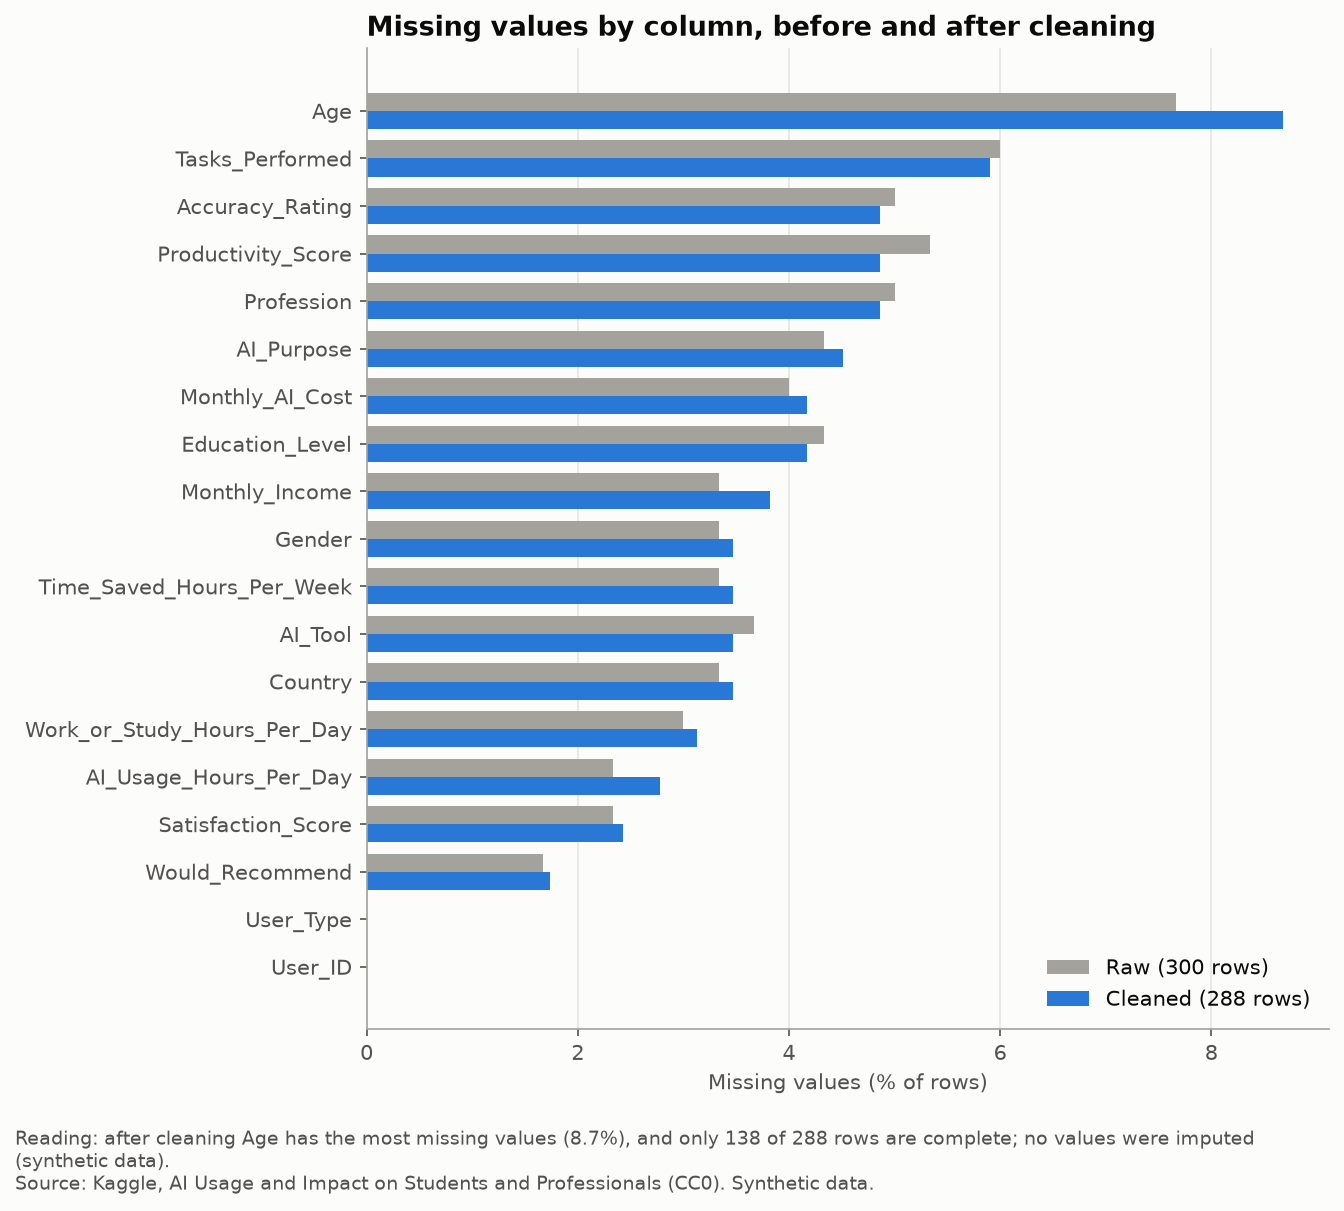

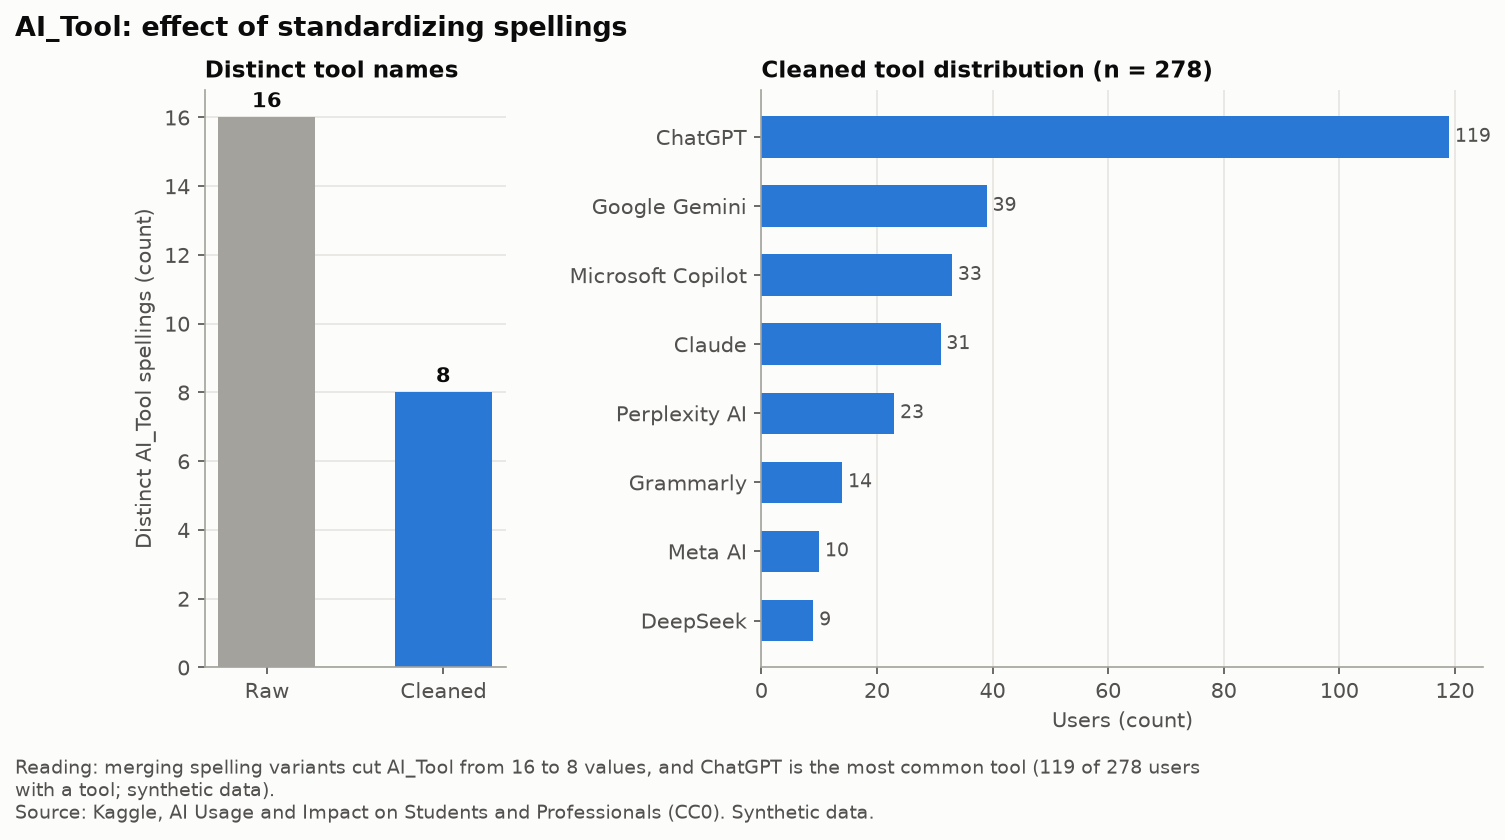

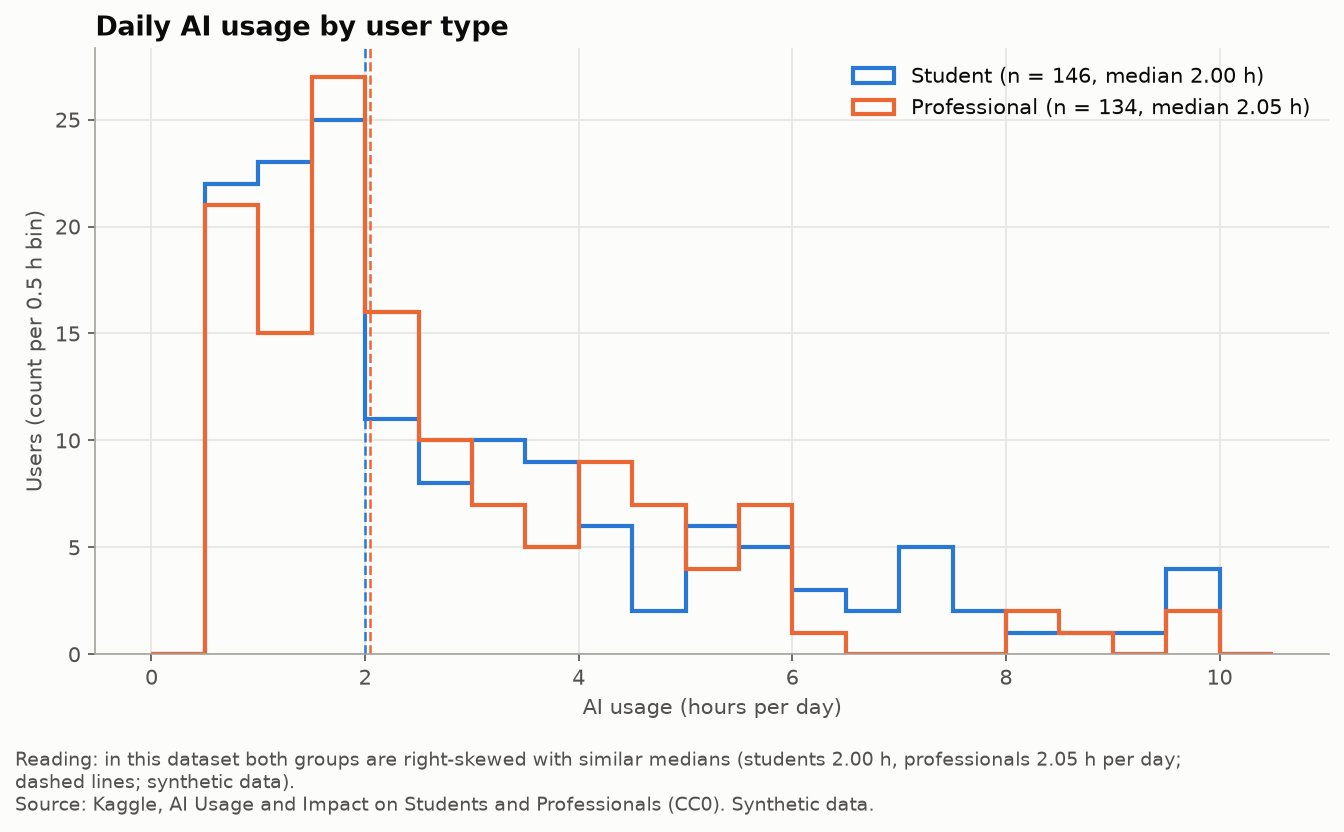

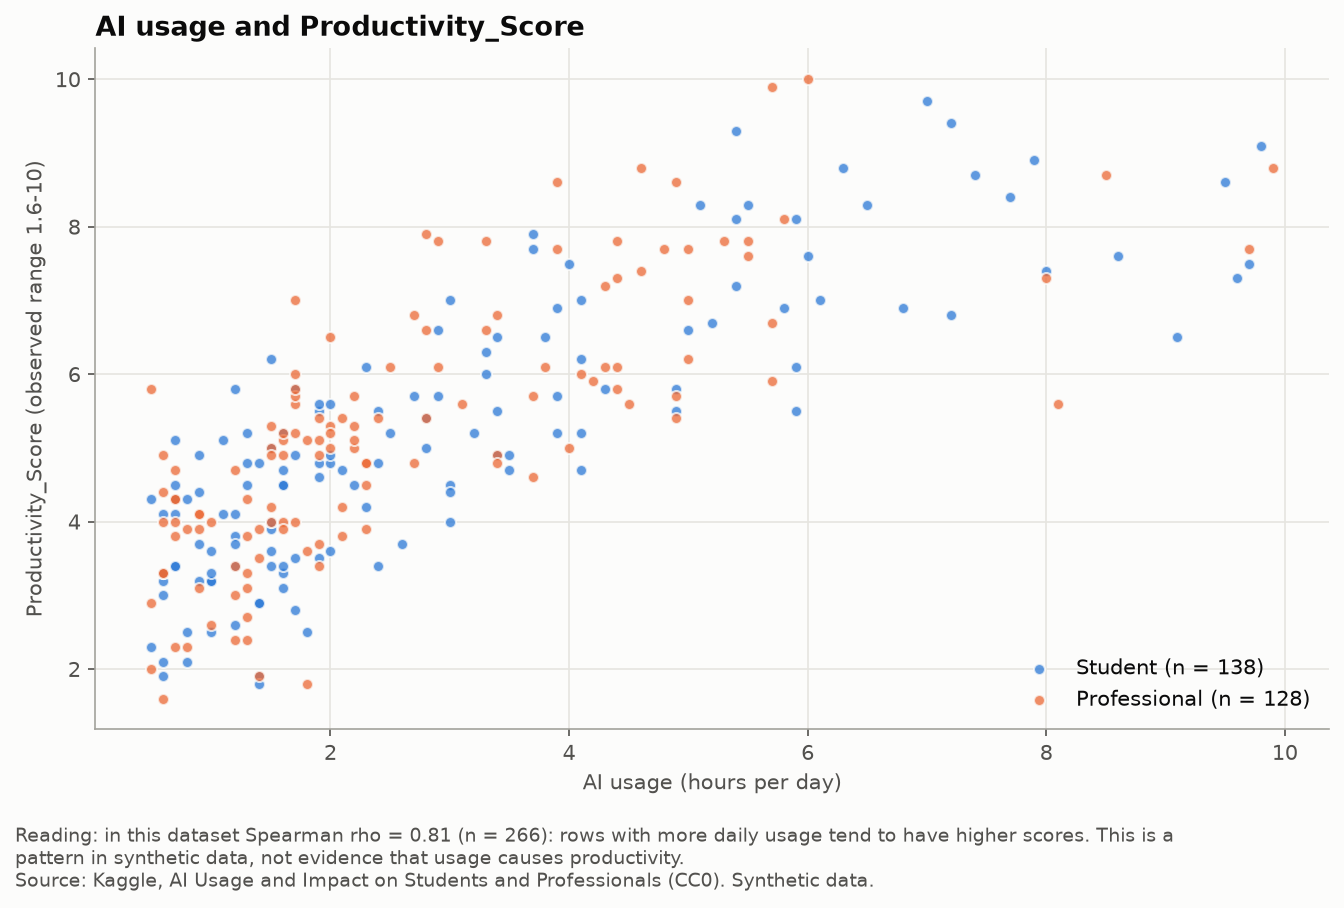

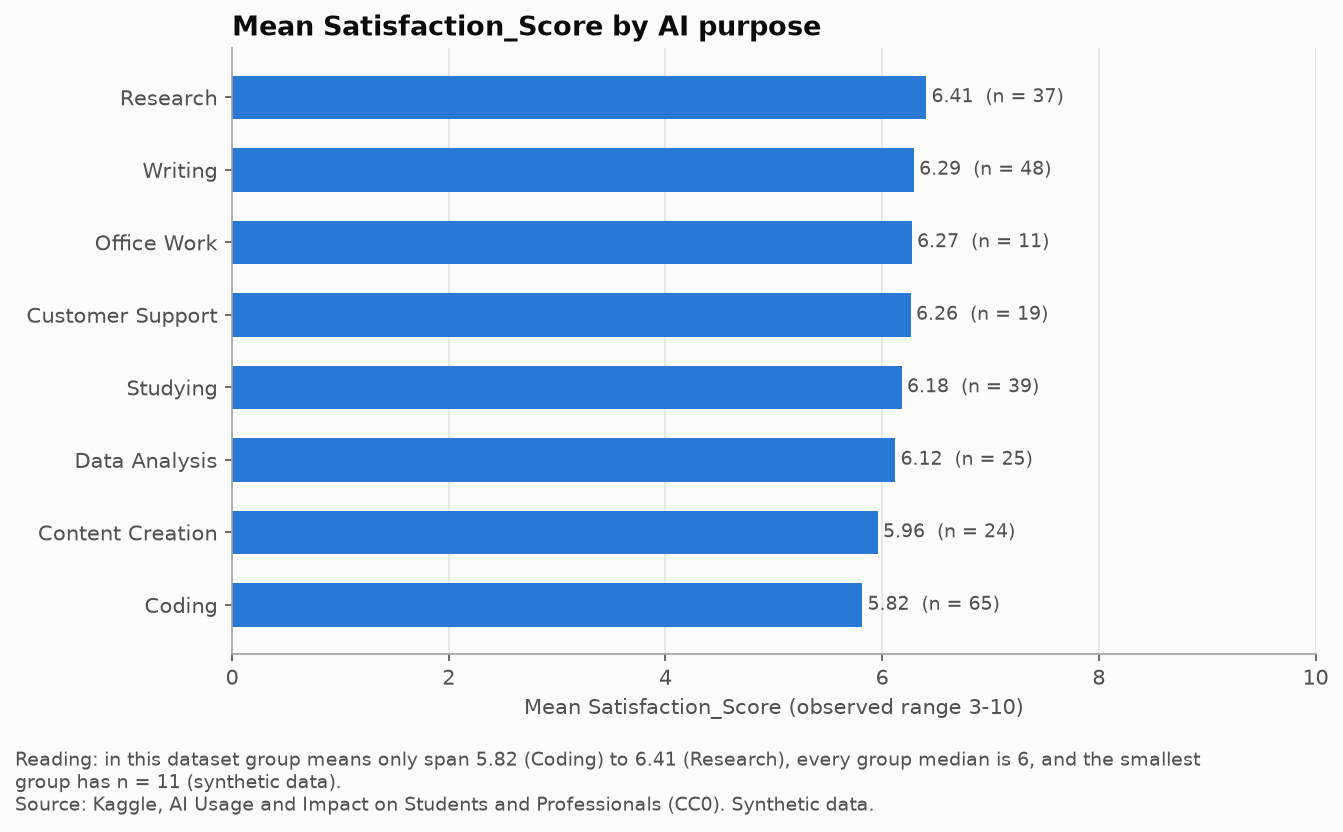

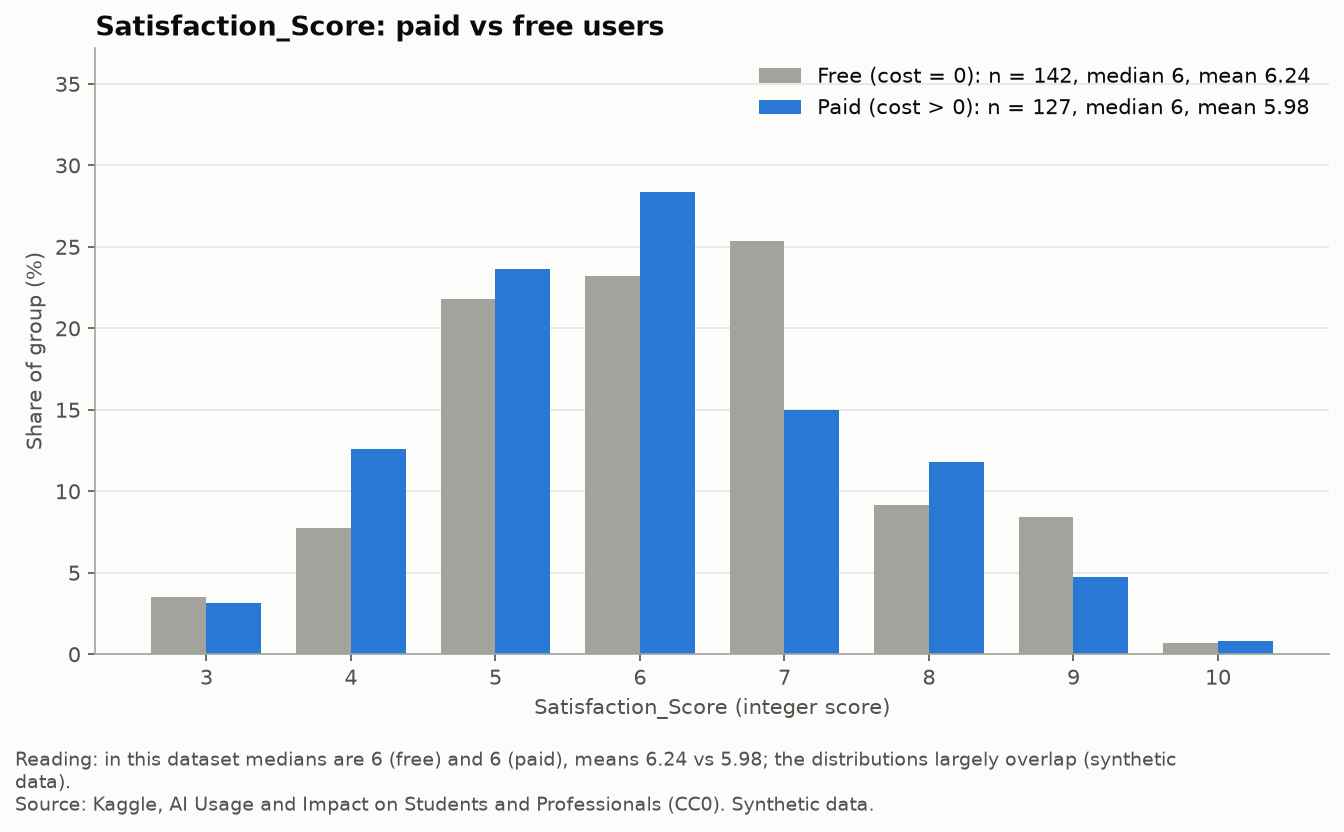

In [18]:
from IPython.display import Image, display
for p in sorted(fg.FIG_DIR.glob("*.png")):
    display(Image(filename=p, width=700))

## 7. Observations, limitations, product takeaway
All numbers come from the cells above. **Synthetic data is a limitation of every finding**; each one also has its own limitation below.

| # | Observation (in this dataset) | Evidence | Specific limitation |
|---|---|---|---|
| 1 | In this dataset, documented cleaning removed 12 exact duplicates (300 → 288), merged AI_Tool 16 → 8, Gender 11 → 3 and Education_Level 16 → 6 spellings, and converted 6 text columns to numbers with 0 failures; only 138 of 288 rows are fully complete, but each single analysis keeps n = 266-280. | Sections 2-3, 5; fig 01, 02 | Some mappings are assumptions (Gemini → Google Gemini, Non-binary → Other); Undergraduate and Bachelor's are kept separate though they likely overlap. |
| 2 | In this dataset, daily AI usage and Productivity_Score rise together in rank (Spearman rho 0.81, n = 266), similarly for students (0.82) and professionals (0.80); usage and Time_Saved show 0.83. | Section 4-5; fig 04 | A monotonic association only; 23 rows report more AI hours than work/study hours and were kept, so the usage column itself is partly inconsistent. |
| 3 | In this dataset, Satisfaction_Score barely varies by group: purpose means range 5.82-6.41 with every median at 6, and paid vs free means are 5.98 vs 6.24, both medians 6. | fig 05, 06 | Integer score with 8 observed levels and small groups (Office Work n = 11); no test was run, so small mean gaps are not interpreted. |

**Product takeaway:** most of the cleaning work here (51 Gender relabels, 16 AI_Tool relabels, 81 numeric cells with units) would be avoided by input validation at collection time: fixed choice lists for categories and numeric-only fields with the unit in the label.